In [1]:
import re, sys
import polars as pl
from pathlib import Path
from plotnine import *
from pprint import pprint

import phonopy
from phonopy import alignment
from phonopy.strings import str_standardize

/home/colin/Library/miniconda3/envs/py3_14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


    ipa syllabic stress long consonantal sonorant continuant delayed.release  \
0     ɒ        +      -    -           -        +          +               0   
1     ɑ        +      -    -           -        +          +               0   
2     ɶ        +      -    -           -        +          +               0   
3     a        +      -    -           -        +          +               0   
4     æ        +      -    -           -        +          +               0   
..   ..      ...    ...  ...         ...      ...        ...             ...   
138   ɹ        -      -    -           -        +          +               0   
139   ʋ        -      -    -           -        +          +               0   
140   ʍ        -      -    -           -        -          +               +   
141   ɦ        -      -    -           -        -          +               +   
142   h        -      -    -           -        -          +               +   

    approximant tap  ... distributed st

In [2]:
# Pronunciation dictionary.
data_dir = Path.home() / "Languages/00Dictionaries/wikipron/data/scrape/tsv"
data_file = "ceb_latn_broad.tsv"

data_df = pl.read_csv(data_dir / data_file, separator="\t", has_header=False, new_columns=["orth", "phon"])
print(data_df.shape)
print(data_df.head())

(4100, 2)
shape: (5, 2)
┌────────┬───────────────┐
│ orth   ┆ phon          │
│ ---    ┆ ---           │
│ str    ┆ str           │
╞════════╪═══════════════╡
│ Abalos ┆ ʔ a b a l o s │
│ Abao   ┆ ʔ aː b a w    │
│ Abapo  ┆ ʔ a b a p o   │
│ Abayon ┆ ʔ a b a j o n │
│ Abello ┆ ʔ a b e l j o │
└────────┴───────────────┘


In [15]:
aligner = alignment.SelfAligner()

alignments = []
for idx, x in enumerate(data_df["phon"].to_list()):
    x = str_standardize(x)
    try:
        saligns = aligner.get_alignment(x, sep=" ", incremental=False)
        score, exact_score, _, salign = saligns[0]
        salign_str = salign.pprint(sep=" ")
        alignments.append((score, exact_score, salign_str))
    except Exception as e:
        print(f"Error aligning {x}")
        print(e)
        alignments.append((None, None, None))
    if idx > 1000:
        break

Error aligning ʔ aː b a w
'aː'
Error aligning b aː b a w
'aː'
Error aligning b a n t aː j a n
'aː'
Error aligning ɛː n a d
'ɛː'
Error aligning dʒ i n a
'n '
Error aligning ʔ ɪ n tʃ i k
'ʔ '
Error aligning dʒ i n
'n '
Error aligning dʒ e n n i p e ɾ
'n '
Error aligning dʒ o s e l i n
's '
Error aligning dʒ o s e p h u s
's '
Error aligning dʒ u n e l i t o
't '
Error aligning dʒ u n m a ɾ
'n '
Error aligning l ɑː n s ə l ɒ t
'ɑː'
Error aligning l a p u l aˑ p u
'aˑ'
Error aligning m i k a b aː l o
'aː'
Error aligning n a n aː m a n
'aː'
Error aligning ɾ e dʒ i n a
'n '
Error aligning s a n tʃ a ŋ k o
's '
Error aligning b iː n̪ ʊ s
'iː'
Error aligning b i s̺ a j a ʔ
's̺'
Error aligning a b ʊ t̪
'b '
Error aligning ʔ a dʒ a w
'ʔ '
Error aligning a l̪ i m p o
'l̪'
Error aligning a l̪ i m p u d ʒ o
'l̪'
Error aligning a l̪ i m p u l̪ o
'l̪'
Error aligning ʔ a l i m p u dʒ o s
'l '


In [16]:
alignments_df = pl.DataFrame(alignments, orient="row", schema=["score", "exact_score", "salign_str"])
alignments_df = alignments_df.sort("score", descending=True)
print(alignments_df)

shape: (1_002, 3)
┌───────┬─────────────┬───────────────┐
│ score ┆ exact_score ┆ salign_str    │
│ ---   ┆ ---         ┆ ---           │
│ f64   ┆ f64         ┆ str           │
╞═══════╪═════════════╪═══════════════╡
│ null  ┆ null        ┆ null          │
│ null  ┆ null        ┆ null          │
│ null  ┆ null        ┆ null          │
│ null  ┆ null        ┆ null          │
│ null  ┆ null        ┆ null          │
│ …     ┆ …           ┆ …             │
│ 0.0   ┆ 0.0         ┆ ⟨ ⟩ k ⟨ ⟩ u   │
│ 0.0   ┆ 0.0         ┆ ⟨ ⟩ l ⟨ ⟩ i   │
│ 0.0   ┆ 0.0         ┆ ⟨ ⟩ p o ⟨ ⟩ l │
│ 0.0   ┆ 0.0         ┆ ⟨ ⟩ s ⟨ ⟩ i   │
│ 0.0   ┆ 0.0         ┆ ⟨ ⟩ ʔ a ⟨ ⟩ ŋ │
└───────┴─────────────┴───────────────┘


/home/colin/Library/miniconda3/envs/py3_14/lib/python3.14/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 26 rows containing non-finite values.


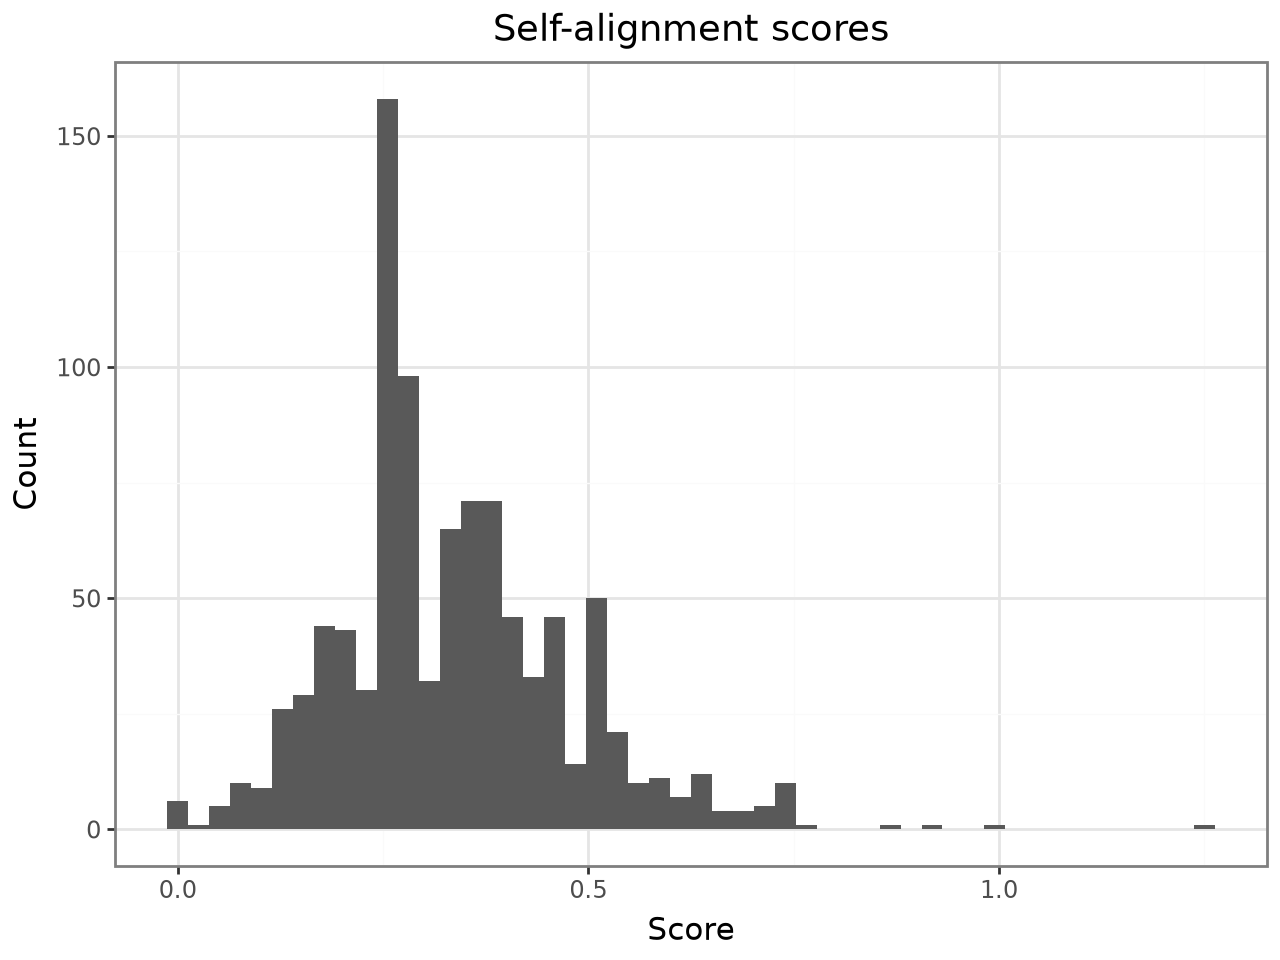

In [17]:
ggplot(alignments_df, aes(x="score")) + geom_histogram(bins=50) + theme_bw() + labs(title="Self-alignment scores", x="Score", y="Count")

In [23]:
alignments_df.filter((pl.col("score") >= 0.7) & (pl.col("exact_score") >= 0.8))

score,exact_score,salign_str
f64,f64,str
1.25,1.0,"""⟨ l a h a j ⟩ ⟨ l a h a j ⟩"""
1.0,1.0,"""⟨ ʔ i l o ⟩ ⟨ ʔ i l o ⟩"""
0.930545,0.8,"""⟨ k a b a n ⟩ ⟨ k a l a n ⟩"""
0.75,1.0,"""⟨ k a ɾ ⟩ ⟨ k a ɾ ⟩"""
0.75,1.0,"""⟨ p i l ⟩ a ⟨ p i l ⟩"""
…,…,…
0.75,1.0,"""ʔ a l i ⟨ b a ŋ ⟩ ⟨ b a ŋ ⟩"""
0.75,1.0,"""a l i ⟨ ŋ a g ⟩ ⟨ ŋ a g ⟩"""
0.75,1.0,"""⟨ dʒ u n ⟩ ⟨ dʒ u n ⟩"""
